## Data Generation

In [1]:
import numpy as np
import pandas as pd

def generate_financial_dataset(n_samples=50000, random_state=42):
    np.random.seed(random_state)
    
    # ---------------------------------------------------------
    # 1. Customer Demographics & Financial Profile
    # ---------------------------------------------------------
    # Age: Skewed distribution (majority 25-55, bounded 18-80)
    age = np.clip(np.random.gamma(shape=9, scale=4, size=n_samples).astype(int), 18, 80)
    
    # Annual Income: Log-normal distribution with long right tail and high-income outliers
    # Mean ~ $65,000 with realistic Pareto-style fat tail
    income_base = np.random.lognormal(mean=10.9, sigma=0.65, size=n_samples)
    # Inject 0.5% extreme high-earning outliers ($500k - $3M)
    high_earners = np.random.rand(n_samples) < 0.005
    income_base[high_earners] = np.random.uniform(500000, 3000000, size=np.sum(high_earners))
    annual_income = np.round(income_base, -2)
    
    # Employment length (in years): positively correlated with age
    emp_length = np.clip(np.random.poisson(lam=(age - 18) * 0.25), 0, 40).astype(float)
    
    # Home Ownership: Categorical with realistic credit market share
    home_ownership = np.random.choice(
        ['MORTGAGE', 'RENT', 'OWN', 'OTHER'],
        size=n_samples,
        p=[0.48, 0.40, 0.11, 0.01]
    )
    
    # ---------------------------------------------------------
    # 2. Credit Profile & Debt Characteristics
    # ---------------------------------------------------------
    # Revolving Credit Utilization: Beta distribution (clustered around 30%, with max > 100%)
    revolving_util = np.random.beta(a=2, b=4, size=n_samples) * 1.15
    # Outliers: maxed-out or over-limit cards (> 100% util)
    revolving_util = np.round(np.clip(revolving_util, 0.0, 1.45), 3)
    
    # Derogatory Marks & Delinquencies: Zero-inflated Poisson (most have 0)
    has_derogs = np.random.rand(n_samples) < 0.18
    derog_marks = np.where(has_derogs, np.random.poisson(lam=1.6, size=n_samples) + 1, 0)
    
    has_delinq = np.random.rand(n_samples) < 0.12
    delinq_2yrs = np.where(has_delinq, np.random.poisson(lam=1.2, size=n_samples) + 1, 0)
    
    # Credit Score (FICO-like 300 - 850):
    # Inversely tied to utilization, delinquencies, and derogs, with natural noise
    credit_score_base = (
        810
        - (revolving_util * 130)
        - (derog_marks * 35)
        - (delinq_2yrs * 40)
        + np.random.normal(0, 30, size=n_samples)
    )
    credit_score = np.clip(np.round(credit_score_base), 300, 850).astype(int)
    
    # Debt-to-Income (DTI) Ratio: Gamma distribution + high-risk fat tails
    dti = np.random.gamma(shape=3.0, scale=0.06, size=n_samples)
    # Inject 1.2% severe distress outliers (DTI > 0.8 up to 2.5)
    severe_debt = np.random.rand(n_samples) < 0.012
    dti[severe_debt] = np.random.uniform(0.85, 2.50, size=np.sum(severe_debt))
    dti = np.round(dti, 4)
    
    # Open Credit Lines: Poisson distributed
    open_credit_lines = np.clip(np.random.poisson(lam=10, size=n_samples), 1, 45)
    
    # ---------------------------------------------------------
    # 3. Loan & Transaction Activity (Credit + Fraud/AML)
    # ---------------------------------------------------------
    # Requested Loan Amount: Skewed, correlated with income
    loan_amount = np.clip(
        np.random.gamma(shape=3.5, scale=4500, size=n_samples) + (annual_income * 0.08),
        1000, 50000
    )
    loan_amount = np.round(loan_amount / 100) * 100  # Round to nearest 100
    
    loan_intent = np.random.choice(
        ['DEBT_CONSOLIDATION', 'CREDIT_CARD', 'HOME_IMPROVEMENT', 'SMALL_BUSINESS', 'MEDICAL', 'PERSONAL'],
        size=n_samples,
        p=[0.45, 0.22, 0.14, 0.08, 0.06, 0.05]
    )
    
    # Transaction Behavior in Past 30 Days (for AML & Fraud detection)
    tx_velocity_24h = np.random.poisson(lam=2.5, size=n_samples)
    avg_tx_amount_30d = np.random.lognormal(mean=4.2, sigma=0.9, size=n_samples)
    
    # Flow-through ratio: (Total Outflows / Total Inflows in 30 days)
    # Normal customers ~ 0.7 - 1.0; Money laundering pass-through accounts ~ 0.98 - 1.05
    flow_through_ratio = np.random.beta(a=8, b=3, size=n_samples) * 1.1
    
    # High-Risk Jurisdiction Flag (AML indicator)
    foreign_tx_risk = np.random.choice([0, 1], size=n_samples, p=[0.965, 0.035])
    
    # Device / Digital Fingerprint Risk Score (Fraud indicator: 0.0 = safe, 1.0 = bot/proxy)
    device_risk_score = np.random.beta(a=1.2, b=8, size=n_samples)
    
    # ---------------------------------------------------------
    # 4. Inject Realistic AML Typologies (Structuring / Smurfing)
    # ---------------------------------------------------------
    # Structuring: deliberate transactions just below $10,000 reporting threshold ($9,000 - $9,950)
    is_structuring_candidate = (np.random.rand(n_samples) < 0.008)  # 0.8% prevalence
    avg_tx_amount_30d[is_structuring_candidate] = np.random.uniform(9100, 9950, size=np.sum(is_structuring_candidate))
    tx_velocity_24h[is_structuring_candidate] += np.random.randint(6, 18, size=np.sum(is_structuring_candidate))
    flow_through_ratio[is_structuring_candidate] = np.random.uniform(0.97, 1.02, size=np.sum(is_structuring_candidate))

    # ---------------------------------------------------------
    # 5. Realistic Ground-Truth Target Generation
    # ---------------------------------------------------------
    # A. Credit Risk: Loan Default (Target 1: Class Imbalance ~ 10-14%)
    credit_logit = (
        -3.8
        + (dti * 2.8)
        + (revolving_util * 2.2)
        - ((credit_score - 600) / 75)
        + (delinq_2yrs * 0.45)
        + (derog_marks * 0.35)
        + (loan_amount / annual_income * 2.5)
        + np.random.normal(0, 0.4, size=n_samples)  # Unobserved risk / noise
    )
    prob_default = 1 / (1 + np.exp(-credit_logit))
    loan_default = (np.random.rand(n_samples) < prob_default).astype(int)
    
    # B. Fraud Detection: Identity / Application Fraud (Target 2: Rare Event ~ 1.2%)
    fraud_logit = (
        -5.5
        + (device_risk_score * 4.2)
        + (tx_velocity_24h * 0.22)
        + ((age < 22).astype(int) * 0.8)
        + ((annual_income > 350000).astype(int) * 0.9)  # High-value spoofing
        + np.random.normal(0, 0.5, size=n_samples)
    )
    prob_fraud = 1 / (1 + np.exp(-fraud_logit))
    is_fraud = (np.random.rand(n_samples) < prob_fraud).astype(int)
    
    # C. AML Flag: Money Laundering Suspicious Activity (Target 3: Very Rare ~ 0.6%)
    aml_score = (
        (is_structuring_candidate * 4.5)
        + (foreign_tx_risk * 2.1)
        + ((flow_through_ratio > 0.96).astype(int) * 1.5)
        + ((avg_tx_amount_30d > 8500).astype(int) * 1.8)
        + (tx_velocity_24h * 0.15)
        + np.random.normal(0, 0.6, size=n_samples)
    )
    aml_flag = (aml_score > 5.2).astype(int)
    
    # ---------------------------------------------------------
    # 6. Realistic Missing Data Patterns (MCAR & MAR)
    # ---------------------------------------------------------
    # "Thin-file" clients (younger, fewer lines) often lack formal credit score or employment data
    emp_missing = (np.random.rand(n_samples) < 0.05) | (age < 21)
    emp_length[emp_missing] = np.nan
    
    score_missing = (np.random.rand(n_samples) < 0.035) | (open_credit_lines <= 1)
    credit_score_with_na = credit_score.astype(float)
    credit_score_with_na[score_missing] = np.nan
    
    # ---------------------------------------------------------
    # Assemble DataFrame
    # ---------------------------------------------------------
    df = pd.DataFrame({
        'customer_id': [f'CUST_{i:07d}' for i in range(1, n_samples + 1)],
        # Demographics
        'age': age,
        'annual_income': annual_income,
        'employment_length_years': emp_length,
        'home_ownership': home_ownership,
        # Credit history
        'credit_score': credit_score_with_na,
        'dti_ratio': dti,
        'open_credit_lines': open_credit_lines,
        'revolving_utilization': revolving_util,
        'derogatory_marks': derog_marks,
        'delinquencies_2yrs': delinq_2yrs,
        # Loan details
        'loan_amount': loan_amount,
        'loan_intent': loan_intent,
        # Behavioral & Transaction metrics
        'avg_tx_amount_30d': np.round(avg_tx_amount_30d, 2),
        'tx_velocity_24h': tx_velocity_24h,
        'flow_through_ratio': np.round(flow_through_ratio, 3),
        'foreign_tx_risk': foreign_tx_risk,
        'device_risk_score': np.round(device_risk_score, 3),
        # Target variables
        'loan_default': loan_default,    # Credit Risk Modeling Target
        'is_fraud': is_fraud,            # Fraud Detection Target
        'aml_flag': aml_flag             # Anti-Money Laundering Target
    })
    
    return df

# Generate 50,000 records
df_financial = generate_financial_dataset(n_samples=50000, random_state=42)

# Quick summary inspection
print("Dataset Shape:", df_financial.shape)
print("\nTarget Class Distribution:")
print("Loan Default Rate: {:.2%}".format(df_financial['loan_default'].mean()))
print("Fraud Rate:        {:.2%}".format(df_financial['is_fraud'].mean()))
print("AML Flag Rate:     {:.2%}".format(df_financial['aml_flag'].mean()))
print("\nMissing Values Count:")
print(df_financial.isnull().sum()[df_financial.isnull().sum() > 0])

Dataset Shape: (50000, 21)

Target Class Distribution:
Loan Default Rate: 13.30%
Fraud Rate:        1.90%
AML Flag Rate:     0.84%

Missing Values Count:
employment_length_years    6512
credit_score               1799
dtype: int64


## Data Investigation and Preprocessing

In [2]:
df_financial.head()

,customer_id,age,annual_income,employment_length_years,home_ownership,credit_score,dti_ratio,open_credit_lines,revolving_utilization,derogatory_marks,...,loan_amount,loan_intent,avg_tx_amount_30d,tx_velocity_24h,flow_through_ratio,foreign_tx_risk,device_risk_score,loan_default,is_fraud,aml_flag
0,CUST_0000001,40,48100.0,4.0,RENT,730.0,0.0562,7,0.021,3,...,15000.0,DEBT_CONSOLIDATION,31.10,3,0.617,0,0.197,0,0,0
1,CUST_0000002,33,30300.0,6.0,MORTGAGE,717.0,0.5617,4,0.667,0,...,29400.0,DEBT_CONSOLIDATION,133.41,1,0.727,0,0.142,0,0,0
2,CUST_0000003,31,31800.0,1.0,MORTGAGE,758.0,0.3761,5,0.685,0,...,41000.0,PERSONAL,65.80,1,0.520,0,0.128,0,0,0
3,CUST_0000004,31,56200.0,2.0,OWN,750.0,0.2462,9,0.129,0,...,16300.0,CREDIT_CARD,711.34,0,0.834,0,0.044,0,0,0
4,CUST_0000005,56,22300.0,10.0,RENT,765.0,0.0056,14,0.308,0,...,29100.0,DEBT_CONSOLIDATION,224.88,3,0.770,0,0.023,0,0,0


In [3]:
df_financial.columns.tolist()

['customer_id',
 'age',
 'annual_income',
 'employment_length_years',
 'home_ownership',
 'credit_score',
 'dti_ratio',
 'open_credit_lines',
 'revolving_utilization',
 'derogatory_marks',
 'delinquencies_2yrs',
 'loan_amount',
 'loan_intent',
 'avg_tx_amount_30d',
 'tx_velocity_24h',
 'flow_through_ratio',
 'foreign_tx_risk',
 'device_risk_score',
 'loan_default',
 'is_fraud',
 'aml_flag']

In [5]:
df_financial.describe()

,age,annual_income,employment_length_years,credit_score,dti_ratio,open_credit_lines,revolving_utilization,derogatory_marks,delinquencies_2yrs,loan_amount,avg_tx_amount_30d,tx_velocity_24h,flow_through_ratio,foreign_tx_risk,device_risk_score,loan_default,is_fraud,aml_flag
count,50000.00000,5.000000e+04,43488.000000,48201.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,35.66188,7.485668e+04,4.805877,733.715255,0.197716,9.99682,0.381890,0.461040,0.263360,21271.34400,177.781902,2.598800,0.801115,0.034220,0.130346,0.132960,0.018980,0.008360
std,11.73371,1.332895e+05,3.503518,64.827531,0.200244,3.15482,0.204662,1.126955,0.809083,9324.23091,861.177709,1.928676,0.141986,0.181796,0.105467,0.339535,0.136456,0.091051
min,18.00000,4.400000e+03,0.000000,334.000000,0.002400,1.00000,0.003000,0.000000,0.000000,2100.00000,1.560000,0.000000,0.157000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,27.00000,3.510000e+04,2.000000,702.000000,0.104400,8.00000,0.222000,0.000000,0.000000,14400.00000,36.677500,1.000000,0.710000,0.000000,0.049000,0.000000,0.000000,0.000000
50%,34.00000,5.450000e+04,4.000000,745.000000,0.161100,10.00000,0.360000,0.000000,0.000000,19800.00000,67.220000,2.000000,0.817000,0.000000,0.104000,0.000000,0.000000,0.000000
75%,43.00000,8.440000e+04,7.000000,778.000000,0.238800,12.00000,0.521000,0.000000,0.000000,26500.00000,124.672500,3.000000,0.908000,0.000000,0.185000,0.000000,0.000000,0.000000
max,80.00000,2.981400e+06,28.000000,850.000000,2.496200,26.00000,1.080000,9.000000,8.000000,50000.00000,9949.830000,24.000000,1.095000,1.000000,0.761000,1.000000,1.000000,1.000000


In [7]:
# Count missing values
df_financial.isnull().sum()

customer_id                   0
age                           0
annual_income                 0
employment_length_years    6512
home_ownership                0
credit_score               1799
dti_ratio                     0
open_credit_lines             0
revolving_utilization         0
derogatory_marks              0
delinquencies_2yrs            0
loan_amount                   0
loan_intent                   0
avg_tx_amount_30d             0
tx_velocity_24h               0
flow_through_ratio            0
foreign_tx_risk               0
device_risk_score             0
loan_default                  0
is_fraud                      0
aml_flag                      0
dtype: int64

In [10]:
# 1. Check exact percentages
missing_summary = df_financial.isnull().mean() * 100
print(missing_summary[missing_summary > 0])

# 2. Check relationship between missingness and target (Crucial in Risk!)
# Does having a missing credit score correlate with higher default?
df_financial['credit_score_isna'] = df_financial['credit_score'].isnull().astype(int)
print(df_financial.groupby('credit_score_isna')['loan_default'].mean())

employment_length_years    13.024
credit_score                3.598
dtype: float64
credit_score_isna
0    0.132964
1    0.132852
Name: loan_default, dtype: float64


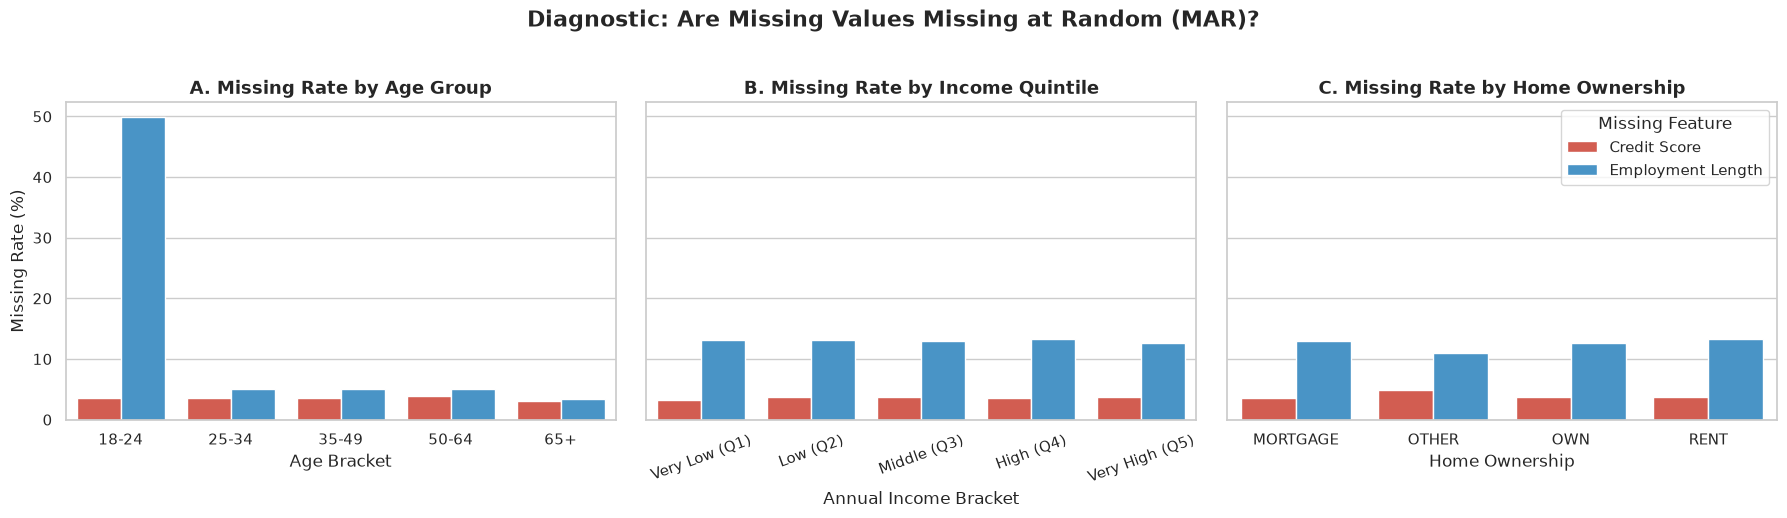

--- Mean Missing Rates by Age Group (%) ---
           missing_credit_score  missing_emp_length
age_group                                          
18-24                  3.555756           49.859345
25-34                  3.584359            5.086894
35-49                  3.592749            5.115286
50-64                  3.822256            5.102617
65+                    3.089598            3.398558


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Set aesthetic style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.size': 11})

# 1. Create binary missing indicators (1 = Missing, 0 = Observed)
df_plot = df_financial.copy()
df_plot['missing_credit_score'] = df_plot['credit_score'].isnull().astype(int)
df_plot['missing_emp_length'] = df_plot['employment_length_years'].isnull().astype(int)

# 2. Bin continuous variables for clear frequency/rate comparisons
df_plot['age_group'] = pd.cut(
    df_plot['age'],
    bins=[17, 24, 34, 49, 64, 100],
    labels=['18-24', '25-34', '35-49', '50-64', '65+']
)

df_plot['income_bracket'] = pd.qcut(
    df_plot['annual_income'],
    q=5,
    labels=['Very Low (Q1)', 'Low (Q2)', 'Middle (Q3)', 'High (Q4)', 'Very High (Q5)']
)

# 3. Helper function to compute missing rates
def get_missing_rates(group_col):
    rates = df_plot.groupby(group_col, observed=True)[['missing_credit_score', 'missing_emp_length']].mean() * 100
    rates = rates.reset_index().melt(
        id_vars=group_col,
        value_vars=['missing_credit_score', 'missing_emp_length'],
        var_name='Feature',
        value_name='Missing_Percentage'
    )
    rates['Feature'] = rates['Feature'].map({
        'missing_credit_score': 'Credit Score',
        'missing_emp_length': 'Employment Length'
    })
    return rates

# 4. Generate the 3-panel diagnostic plot
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

# Panel 1: Missing Rate vs. Age Group
rates_age = get_missing_rates('age_group')
sns.barplot(data=rates_age, x='age_group', y='Missing_Percentage', hue='Feature', ax=axes[0], palette=['#e74c3c', '#3498db'])
axes[0].set_title('A. Missing Rate by Age Group', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Age Bracket')
axes[0].set_ylabel('Missing Rate (%)')
axes[0].legend_.remove()

# Panel 2: Missing Rate vs. Income Bracket
rates_income = get_missing_rates('income_bracket')
sns.barplot(data=rates_income, x='income_bracket', y='Missing_Percentage', hue='Feature', ax=axes[1], palette=['#e74c3c', '#3498db'])
axes[1].set_title('B. Missing Rate by Income Quintile', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Annual Income Bracket')
axes[1].tick_params(axis='x', rotation=20)
axes[1].legend_.remove()

# Panel 3: Missing Rate vs. Home Ownership
rates_home = get_missing_rates('home_ownership')
sns.barplot(data=rates_home, x='home_ownership', y='Missing_Percentage', hue='Feature', ax=axes[2], palette=['#e74c3c', '#3498db'])
axes[2].set_title('C. Missing Rate by Home Ownership', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Home Ownership')
axes[2].legend(title='Missing Feature', loc='upper right')

plt.suptitle('Diagnostic: Are Missing Values Missing at Random (MAR)?', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# 5. Quick tabular summary
print("--- Mean Missing Rates by Age Group (%) ---")
print(df_plot.groupby('age_group', observed=True)[['missing_credit_score', 'missing_emp_length']].mean() * 100)

##### The missing values are MCAR for credit score and MAR for employment length because of the age bracket.
##### Let's see if the default rates for those with missing and not missing values are the same.

In [12]:
# Check if applicants with missing values default at a different rate
print(df_financial.groupby(df_financial['credit_score'].isnull())['loan_default'].mean())
print(df_financial.groupby(df_financial['employment_length_years'].isnull())['loan_default'].mean())

credit_score
False    0.132964
True     0.132852
Name: loan_default, dtype: float64
employment_length_years
False    0.132450
True     0.136364
Name: loan_default, dtype: float64


##### Since the default rates are mostly similar for those with missing and not missing values, I can use a standard imputer.
##### But before imputation, I will first perform a train and test split so that any statistic that I compute will be learned only from training set, avoiding data leakage.

In [14]:
from sklearn.model_selection import train_test_split

# Drop features of potential labels and non-predictive feature
X = df_financial.drop(columns=['loan_default', 'is_fraud', 'aml_flag', 'customer_id'])
y_credit = df_financial['loan_default']

X_train, X_test, y_train, y_test = train_test_split(
    X, y_credit, test_size=0.2, random_state=42, stratify=y_credit
)

In [15]:
# Avoid SettingWithCopy warnings
X_train = X_train.copy()
X_test = X_test.copy()
# -------------------------------------------------------------
# A. Add Missing Indicators (Crucial for capturing risk signal)
# -------------------------------------------------------------
X_train['credit_score_was_missing'] = X_train['credit_score'].isnull().astype(int)
X_test['credit_score_was_missing'] = X_test['credit_score'].isnull().astype(int)
X_train['emp_len_was_missing'] = X_train['employment_length_years'].isnull().astype(int)
X_test['emp_len_was_missing'] = X_test['employment_length_years'].isnull().astype(int)
# -------------------------------------------------------------
# B. Impute employment_length_years by Age Bracket Median
# -------------------------------------------------------------
# Create age brackets
age_bins = [17, 24, 34, 49, 64, 100]
age_labels = ['18-24', '25-34', '35-49', '50-64', '65+']
X_train['age_group'] = pd.cut(X_train['age'], bins=age_bins, labels=age_labels)
X_test['age_group'] = pd.cut(X_test['age'], bins=age_bins, labels=age_labels)
# Compute medians STRICTLY from X_train
emp_median_map = X_train.groupby('age_group', observed=True)['employment_length_years'].median()
print("Learned Employment Medians by Age Cohort:")
print(emp_median_map)
# Map and fill missing values
X_train['employment_length_years'] = X_train['employment_length_years'].fillna(
    X_train['age_group'].map(emp_median_map)
)
X_test['employment_length_years'] = X_test['employment_length_years'].fillna(
    X_test['age_group'].map(emp_median_map)
)
# Clean up temporary grouping column if not needed as a categorical feature
X_train.drop(columns=['age_group'], inplace=True)
X_test.drop(columns=['age_group'], inplace=True)
# -------------------------------------------------------------
# C. Impute credit_score with Global Training Median
# -------------------------------------------------------------
global_credit_median = X_train['credit_score'].median()
print(f"\nLearned Global Credit Score Median: {global_credit_median}")
X_train['credit_score'] = X_train['credit_score'].fillna(global_credit_median)
X_test['credit_score'] = X_test['credit_score'].fillna(global_credit_median)
# Verification
print("\nMissing values remaining in X_train:", X_train.isnull().sum().sum())
print("Missing values remaining in X_test: ", X_test.isnull().sum().sum())

Learned Employment Medians by Age Cohort:
age_group
18-24     1.0
25-34     3.0
35-49     5.0
50-64     9.0
65+      13.0
Name: employment_length_years, dtype: float64

Learned Global Credit Score Median: 745.0

Missing values remaining in X_train: 0
Missing values remaining in X_test:  0


##### The imputation is now finished for the numerical values.
##### Next step is to consider the categorical features by encoding them into numerical features. Also, since the features have different scales, I will also scale the features now.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, RobustScaler

# 1. Define feature groups
skewed_money_cols = [
    'annual_income',
    'loan_amount',
    'avg_tx_amount_30d',
    'dti_ratio',
]
other_num_cols = [
    'age',
    'credit_score',
    'open_credit_lines',
    'revolving_utilization',
    'delinquencies_2yrs',
    'derogatory_marks',
    'tx_velocity_24h',
    'flow_through_ratio',
    'device_risk_score',
]
binary_cols = [
    'foreign_tx_risk',
    'credit_score_was_missing',
    'emp_len_was_missing',
]
cat_cols = ['home_ownership', 'loan_intent']

# 2. Build targeted multi-pipeline preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        (
            'power',
            PowerTransformer(method='yeo-johnson'),
            skewed_money_cols,
        ),  # Turns fat tails into bell curves
        ('robust', RobustScaler(), other_num_cols),  # Handles outliers safely
        ('bin', 'passthrough', binary_cols),  # Keeps 0/1 as 0/1
        (
            'cat',
            OneHotEncoder(
                drop='first', sparse_output=False, handle_unknown='ignore'
            ),
            cat_cols,
        ),
    ],
    verbose_feature_names_out=False,
)

# 3. Fit on train, transform both
X_train_final = pd.DataFrame(
    preprocessor.fit_transform(X_train),
    columns=preprocessor.get_feature_names_out(),
    index=X_train.index,
)
X_test_final = pd.DataFrame(
    preprocessor.transform(X_test),
    columns=preprocessor.get_feature_names_out(),
    index=X_test.index,
)

In [17]:
# Create the complete cleaned training dataset
df_cleaned = X_train_final.copy()
df_cleaned['loan_default'] = y_train.values

display(df_cleaned.head())

,annual_income,loan_amount,avg_tx_amount_30d,dti_ratio,age,credit_score,open_credit_lines,revolving_utilization,delinquencies_2yrs,derogatory_marks,...,emp_len_was_missing,home_ownership_OTHER,home_ownership_OWN,home_ownership_RENT,loan_intent_DEBT_CONSOLIDATION,loan_intent_HOME_IMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_SMALL_BUSINESS,loan_default
21811,-0.205554,-1.053035,-0.288077,-0.307432,-0.1875,0.630137,0.50,-0.367003,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0
411,-0.588177,0.794813,0.739146,0.407255,0.5000,0.369863,0.00,-0.080808,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0
11367,0.511375,1.105052,0.504325,0.140204,-0.1250,0.657534,-0.25,0.043771,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0
5205,-1.605852,0.974419,0.708134,1.703878,0.2500,0.945205,-0.75,0.003367,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1
45113,-0.018203,-1.579818,0.371845,-0.285188,-0.0625,1.301370,-0.25,-0.828283,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0


##### The dataset is not fully pre-processed and scaled. I will now move on to model building and evaluation.

## Modeling and Evaluation

##### Because only a small portion of people defaults, we need to use the right metric where accuracy is meaningless. I will use ROC-AUC and PR-AUC. For models, I will use linear, tree, and neural networks for comparison.

### 1. Logistic Regression (baseline)

In [38]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import average_precision_score, roc_auc_score

# -------------------------------------------------------------
# 1. Master Cross-Validation Setup
# -------------------------------------------------------------
# 5 Folds, stratified to preserve the ~11% default rate in every fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define the two metrics we care about
scoring = {
    'pr_auc': 'average_precision',
    'roc_auc': 'roc_auc'
}

# Master list to store all 4 models as we build them
benchmark_results = []

# -------------------------------------------------------------
# 2. Model 1: Logistic Regression (Baseline)
# -------------------------------------------------------------
log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

# Run 5-Fold Cross-Validation on the training data
cv_results_lr = cross_validate(
    estimator=log_reg,
    X=X_train_final,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

# Also fit on full training set and evaluate on test set for final verification
log_reg.fit(X_train_final, y_train)
y_pred_test_prob = log_reg.predict_proba(X_test_final)[:, 1]

test_pr_auc = average_precision_score(y_test, y_pred_test_prob)
test_roc_auc = roc_auc_score(y_test, y_pred_test_prob)

# -------------------------------------------------------------
# 3. Log Results to Master Benchmark Table
# -------------------------------------------------------------
benchmark_results.append({
    'Model': '1. Logistic Regression (Baseline)',
    'CV PR-AUC (Mean)': round(cv_results_lr['test_pr_auc'].mean(), 4),
    'CV PR-AUC (Std)': round(cv_results_lr['test_pr_auc'].std(), 4),
    'CV ROC-AUC (Mean)': round(cv_results_lr['test_roc_auc'].mean(), 4),
    'Test PR-AUC': round(test_pr_auc, 4),
    'Test ROC-AUC': round(test_roc_auc, 4)
})

# Display current standing
df_benchmark = pd.DataFrame(benchmark_results)
print("=== CROSS-VALIDATION BENCHMARK ===")
display(df_benchmark)

=== CROSS-VALIDATION BENCHMARK ===


,Model,CV PR-AUC (Mean),CV PR-AUC (Std),CV ROC-AUC (Mean),Test PR-AUC,Test ROC-AUC
0,1. Logistic Regression (Baseline),0.606,0.0231,0.87,0.6062,0.8695


### 2. XGBoost

In [39]:
import xgboost as xgb
from sklearn.model_selection import cross_validate
from sklearn.metrics import average_precision_score, roc_auc_score

# 1. Calculate class imbalance ratio for scale_pos_weight
# Ratio of non-defaulters (0) to defaulters (1)
scale_pos_weight_value = (y_train == 0).sum() / (y_train == 1).sum()

# 2. Instantiate XGBoost Classifier with curated parameters
xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight_value,
    eval_metric='aucpr',
    random_state=42,
    n_jobs=-1
)

# 3. Run 5-Fold Stratified Cross-Validation
cv_results_xgb = cross_validate(
    estimator=xgb_model,
    X=X_train_final,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

# 4. Fit on full training set and score on holdout test set
xgb_model.fit(X_train_final, y_train)
y_pred_xgb_prob = xgb_model.predict_proba(X_test_final)[:, 1]

test_pr_auc_xgb = average_precision_score(y_test, y_pred_xgb_prob)
test_roc_auc_xgb = roc_auc_score(y_test, y_pred_xgb_prob)

# 5. Append to Master Benchmark Table
benchmark_results.append({
    'Model': '2. XGBoost',
    'CV PR-AUC (Mean)': round(cv_results_xgb['test_pr_auc'].mean(), 4),
    'CV PR-AUC (Std)': round(cv_results_xgb['test_pr_auc'].std(), 4),
    'CV ROC-AUC (Mean)': round(cv_results_xgb['test_roc_auc'].mean(), 4),
    'Test PR-AUC': round(test_pr_auc_xgb, 4),
    'Test ROC-AUC': round(test_roc_auc_xgb, 4)
})

# Display updated comparison table
df_benchmark = pd.DataFrame(benchmark_results)
print("=== UPDATED MODEL BENCHMARK ===")
display(df_benchmark)

=== UPDATED MODEL BENCHMARK ===


,Model,CV PR-AUC (Mean),CV PR-AUC (Std),CV ROC-AUC (Mean),Test PR-AUC,Test ROC-AUC
0,1. Logistic Regression (Baseline),0.6060,0.0231,0.8700,0.6062,0.8695
1,2. XGBoost,0.6301,0.0219,0.8764,0.6375,0.8791


### 3. LightBGM

In [40]:
import lightgbm as lgb
from sklearn.model_selection import cross_validate
from sklearn.metrics import average_precision_score, roc_auc_score

# 1. Instantiate LightGBM Classifier
# LightGBM uses leaf-wise tree growth for faster execution and deeper feature interaction
lgb_model = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=24,             # Controls tree complexity (leaf-wise equivalent of max_depth)
    max_depth=5,
    subsample=0.8,
    subsample_freq=1,          # Apply bagging at every single iteration
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight_value,  # ~8.1 to balance default class
    random_state=42,
    n_jobs=-1,
    verbose=-1                # Suppress noisy training logs
)

# 2. Run 5-Fold Stratified Cross-Validation
cv_results_lgb = cross_validate(
    estimator=lgb_model,
    X=X_train_final,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

# 3. Fit on full training set and score on holdout test set
lgb_model.fit(X_train_final, y_train)
y_pred_lgb_prob = lgb_model.predict_proba(X_test_final)[:, 1]

test_pr_auc_lgb = average_precision_score(y_test, y_pred_lgb_prob)
test_roc_auc_lgb = roc_auc_score(y_test, y_pred_lgb_prob)

# 4. Append to Master Benchmark Table
benchmark_results.append({
    'Model': '3. LightGBM',
    'CV PR-AUC (Mean)': round(cv_results_lgb['test_pr_auc'].mean(), 4),
    'CV PR-AUC (Std)': round(cv_results_lgb['test_pr_auc'].std(), 4),
    'CV ROC-AUC (Mean)': round(cv_results_lgb['test_roc_auc'].mean(), 4),
    'Test PR-AUC': round(test_pr_auc_lgb, 4),
    'Test ROC-AUC': round(test_roc_auc_lgb, 4)
})

# Display updated comparison table
df_benchmark = pd.DataFrame(benchmark_results)
print("=== UPDATED 3-MODEL BENCHMARK ===")
display(df_benchmark)

=== UPDATED 3-MODEL BENCHMARK ===


,Model,CV PR-AUC (Mean),CV PR-AUC (Std),CV ROC-AUC (Mean),Test PR-AUC,Test ROC-AUC
0,1. Logistic Regression (Baseline),0.6060,0.0231,0.8700,0.6062,0.8695
1,2. XGBoost,0.6301,0.0219,0.8764,0.6375,0.8791
2,3. LightGBM,0.6315,0.0214,0.8772,0.6395,0.8787


### 4. NN - MLP

In [41]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import cross_validate
from sklearn.metrics import average_precision_score, roc_auc_score

# 1. Instantiate the Multi-Layer Perceptron (MLP)
mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),    # 2 Hidden Layers: 64 neurons -> 32 neurons
    activation='relu',              # Rectified Linear Unit for non-linear feature blending
    solver='adam',                  # Adaptive gradient descent optimizer
    alpha=0.01,                     # L2 Regularization penalty (prevents overfitting)
    batch_size=256,                 # Mini-batch size for smooth gradient updates
    learning_rate_init=0.001,       # Initial learning step size
    max_iter=150,                   # Maximum training epochs
    early_stopping=True,            # Stops training if internal validation stops improving
    n_iter_no_change=10,            # Patience of 10 epochs before triggering early stop
    random_state=42
)

# 2. Run 5-Fold Stratified Cross-Validation
cv_results_mlp = cross_validate(
    estimator=mlp_model,
    X=X_train_final,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

# 3. Fit on full training set and score on holdout test set
mlp_model.fit(X_train_final, y_train)
y_pred_mlp_prob = mlp_model.predict_proba(X_test_final)[:, 1]

test_pr_auc_mlp = average_precision_score(y_test, y_pred_mlp_prob)
test_roc_auc_mlp = roc_auc_score(y_test, y_pred_mlp_prob)

# 4. Append to Master Benchmark Table
benchmark_results.append({
    'Model': '4. Neural Network - MLP',
    'CV PR-AUC (Mean)': round(cv_results_mlp['test_pr_auc'].mean(), 4),
    'CV PR-AUC (Std)': round(cv_results_mlp['test_pr_auc'].std(), 4),
    'CV ROC-AUC (Mean)': round(cv_results_mlp['test_roc_auc'].mean(), 4),
    'Test PR-AUC': round(test_pr_auc_mlp, 4),
    'Test ROC-AUC': round(test_roc_auc_mlp, 4)
})

# Display 4-Model Leaderboard
df_benchmark = pd.DataFrame(benchmark_results)
print("=== UPDATED 4-MODEL BENCHMARK ===")
display(df_benchmark)

=== UPDATED 4-MODEL BENCHMARK ===


,Model,CV PR-AUC (Mean),CV PR-AUC (Std),CV ROC-AUC (Mean),Test PR-AUC,Test ROC-AUC
0,1. Logistic Regression (Baseline),0.6060,0.0231,0.8700,0.6062,0.8695
1,2. XGBoost,0.6301,0.0219,0.8764,0.6375,0.8791
2,3. LightGBM,0.6315,0.0214,0.8772,0.6395,0.8787
3,4. Neural Network - MLP,0.6241,0.0192,0.8764,0.6318,0.8739


### Random Forest

In [42]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate
from sklearn.metrics import average_precision_score, roc_auc_score

# 1. Instantiate the Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=300,                  # 300 independent decision trees in the committee
    max_depth=12,                      # Deep enough for complex patterns, but constrained against memorizing noise
    min_samples_split=10,              # Requires at least 10 borrowers to create a new split
    min_samples_leaf=4,                # Minimum 4 borrowers required in each leaf node
    max_features='sqrt',               # At each split, randomly considers only ~sqrt(20) = 4-5 features
    class_weight='balanced_subsample', # Recalculates balanced class weights per bootstrap sample
    random_state=42,
    n_jobs=-1                          # Trains all trees in parallel across all CPU cores
)

# 2. Run 5-Fold Stratified Cross-Validation
cv_results_rf = cross_validate(
    estimator=rf_model,
    X=X_train_final,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

# 3. Fit on full training set and score on holdout test set
rf_model.fit(X_train_final, y_train)
y_pred_rf_prob = rf_model.predict_proba(X_test_final)[:, 1]

test_pr_auc_rf = average_precision_score(y_test, y_pred_rf_prob)
test_roc_auc_rf = roc_auc_score(y_test, y_pred_rf_prob)

# 4. Append to Master Benchmark Table
benchmark_results.append({
    'Model': '5. Random Forest',
    'CV PR-AUC (Mean)': round(cv_results_rf['test_pr_auc'].mean(), 4),
    'CV PR-AUC (Std)': round(cv_results_rf['test_pr_auc'].std(), 4),
    'CV ROC-AUC (Mean)': round(cv_results_rf['test_roc_auc'].mean(), 4),
    'Test PR-AUC': round(test_pr_auc_rf, 4),
    'Test ROC-AUC': round(test_roc_auc_rf, 4)
})

# Display Final 5-Model Leaderboard
df_benchmark = pd.DataFrame(benchmark_results)
print("=" * 70)
print("          COMPLETE 5-MODEL CREDIT RISK LEADERBOARD")
print("=" * 70)
display(df_benchmark.sort_values(by='CV PR-AUC (Mean)', ascending=False))

          COMPLETE 5-MODEL CREDIT RISK LEADERBOARD


,Model,CV PR-AUC (Mean),CV PR-AUC (Std),CV ROC-AUC (Mean),Test PR-AUC,Test ROC-AUC
2,3. LightGBM,0.6315,0.0214,0.8772,0.6395,0.8787
1,2. XGBoost,0.6301,0.0219,0.8764,0.6375,0.8791
3,4. Neural Network - MLP,0.6241,0.0192,0.8764,0.6318,0.8739
0,1. Logistic Regression (Baseline),0.6060,0.0231,0.8700,0.6062,0.8695
4,5. Random Forest,0.5905,0.0183,0.8728,0.5975,0.8731


### SHAP on LightGBM Model

In [44]:
# 1. Install shap inside your notebook kernel (if needed)
# pip install shap -q

import shap
import matplotlib.pyplot as plt
import numpy as np

# 2. Initialize the TreeExplainer for the winning LightGBM model
# TreeExplainer is heavily optimized in C++ and computes exact Shapley values in seconds
explainer = shap.TreeExplainer(lgb_model)

# 3. Compute SHAP values for the test set
# We take a sample of 2,000 test applicants for instant plotting
X_sample = X_test_final.sample(2000, random_state=42)
shap_values = explainer(X_sample)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


##### Let use see how are features factored in the decision of the LightGBM model.
##### Aside from that, let's look also an example of a predicted defaulter and non-defaulter and see what features affected the decision.

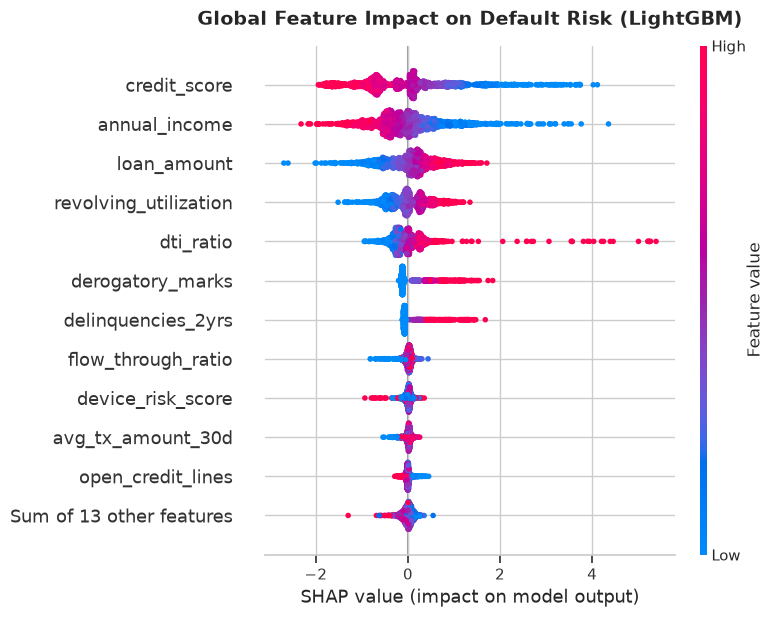

In [49]:
plt.figure(figsize=(10, 6))
plt.title("Global Feature Impact on Default Risk (LightGBM)", fontsize=14, fontweight='bold', pad=15)

# Beeswarm plot showing magnitude and direction of each feature
shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.tight_layout()
plt.show()

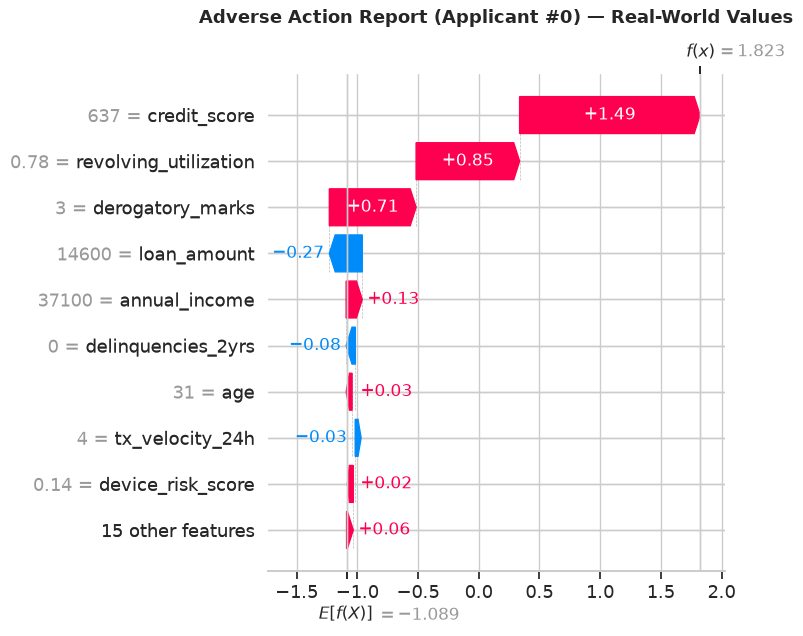

       ADVERSE ACTION NOTICE: APPLICANT #0
Predicted Probability of Default: 86.09%
Ground Truth Outcome:             DEFAULTED (1)

Top Reasons for Credit Decline (Ranked by Risk Contribution):


,Feature,Original_Applicant_Value,SHAP_Risk_Impact
0,credit_score,637.00,1.486335
1,revolving_utilization,0.78,0.852571
2,derogatory_marks,3.00,0.714552
3,annual_income,37100.00,0.132614
4,age,31.00,0.026729


In [47]:
import copy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

# 1. Identify a high-risk applicant (predicted probability of default > 70%)
high_risk_candidates = np.where(y_pred_lgb_prob > 0.70)[0]
target_applicant_idx = high_risk_candidates[0]

# 2. Extract their SHAP explanation object
# Use deepcopy so we can modify the display values without affecting the original object
shap_single = copy.deepcopy(
    explainer(X_test_final.iloc[[target_applicant_idx]])[0]
)

# 3. Retrieve their ORIGINAL unscaled record from X_test
orig_row = X_test.iloc[target_applicant_idx]

# 4. Map the original real-world values into the SHAP display array
unscaled_display_values = []
for col in X_test_final.columns:
  if col in orig_row.index:
    # Use the raw number (e.g. $52,000, 610 credit score, 0.45 DTI)
    val = orig_row[col]
    unscaled_display_values.append(
        round(val, 2) if isinstance(val, (int, float)) else val
    )
  else:
    # For one-hot encoded dummies (e.g. home_ownership_RENT = 1), keep the 0 or 1
    unscaled_display_values.append(
        X_test_final.iloc[target_applicant_idx][col]
    )

# Overwrite the scaled z-scores with the real-world values for the plot
shap_single.data = np.array(unscaled_display_values)

# 5. Render the Unscaled Waterfall Plot
plt.figure(figsize=(11, 6))
shap.plots.waterfall(shap_single, max_display=10, show=False)
plt.title(
    f"Adverse Action Report (Applicant #{target_applicant_idx}) — Real-World"
    " Values",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 6. Print the Official Banking "Adverse Action Notice" Table
# -------------------------------------------------------------
# Pull top positive contributors (the exact reasons for loan decline)
reasons_df = pd.DataFrame(
    {
        "Feature": X_test_final.columns,
        "Original_Applicant_Value": unscaled_display_values,
        "SHAP_Risk_Impact": shap_single.values,
    }
).sort_values(by="SHAP_Risk_Impact", ascending=False)

print("=" * 65)
print(f"       ADVERSE ACTION NOTICE: APPLICANT #{target_applicant_idx}")
print("=" * 65)
print(
    f"Predicted Probability of Default: {y_pred_lgb_prob[target_applicant_idx]:.2%}"
)
print(
    "Ground Truth Outcome:            "
    f" {'DEFAULTED (1)' if y_test.iloc[target_applicant_idx] == 1 else 'PAID OFF (0)'}\n"
)
print("Top Reasons for Credit Decline (Ranked by Risk Contribution):")
display(reasons_df.head(5).reset_index(drop=True))

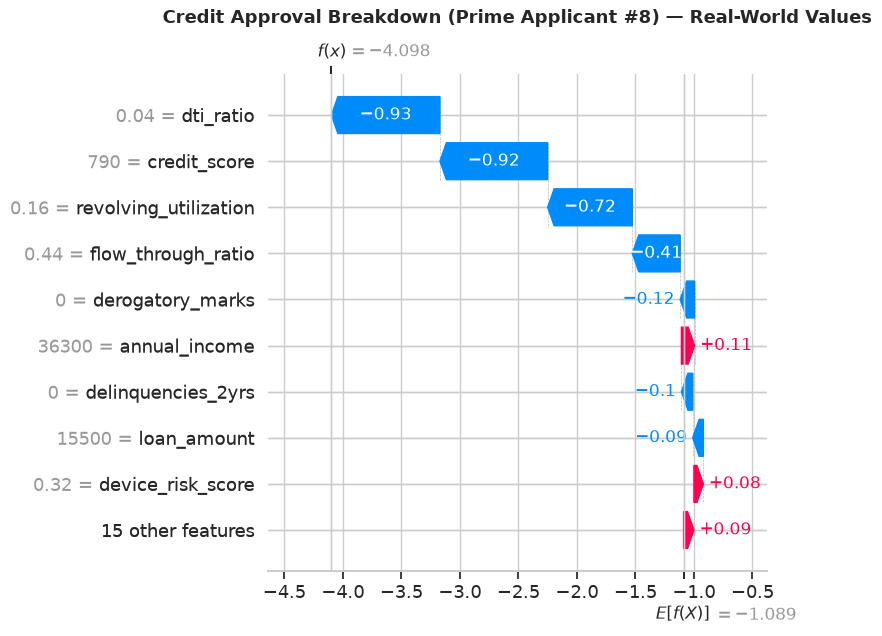

       CREDIT APPROVAL MEMO: APPLICANT #8
Predicted Probability of Default: 1.63%
Ground Truth Outcome:             PAID OFF (0)

Top Positive Credit Strengths (Why this loan was approved):


,Feature,Applicant_Actual_Value,SHAP_Protective_Impact
0,dti_ratio,0.04,-0.927378
1,credit_score,790.00,-0.920477
2,revolving_utilization,0.16,-0.723379
3,flow_through_ratio,0.44,-0.409060
4,derogatory_marks,0.00,-0.122735


In [48]:
import copy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

# 1. Identify a prime, ultra-safe applicant (predicted default probability < 2%)
low_risk_candidates = np.where(y_pred_lgb_prob < 0.02)[0]

# Pick the safest candidate or the first one below 2%
if len(low_risk_candidates) > 0:
  target_safe_idx = low_risk_candidates[0]
else:
  target_safe_idx = np.argmin(y_pred_lgb_prob)  # Lowest risk in entire test set

# 2. Extract their SHAP explanation object
shap_safe = copy.deepcopy(explainer(X_test_final.iloc[[target_safe_idx]])[0])

# 3. Retrieve their ORIGINAL unscaled record from X_test
orig_safe_row = X_test.iloc[target_safe_idx]

# 4. Map the original real-world values into the SHAP display array
unscaled_safe_values = []
for col in X_test_final.columns:
  if col in orig_safe_row.index:
    val = orig_safe_row[col]
    unscaled_safe_values.append(
        round(val, 2) if isinstance(val, (int, float)) else val
    )
  else:
    unscaled_safe_values.append(X_test_final.iloc[target_safe_idx][col])

# Overwrite display data with real-world numbers
shap_safe.data = np.array(unscaled_safe_values)

# 5. Render the Waterfall Plot (Dominated by Blue Protective Arrows)
plt.figure(figsize=(11, 6))
shap.plots.waterfall(shap_safe, max_display=10, show=False)
plt.title(
    f"Credit Approval Breakdown (Prime Applicant #{target_safe_idx}) —"
    " Real-World Values",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 6. Print the Official "Approval Strengths" Table
# -------------------------------------------------------------
# Pull top negative contributors (factors that protected and lowered their risk)
strengths_df = pd.DataFrame(
    {
        "Feature": X_test_final.columns,
        "Applicant_Actual_Value": unscaled_safe_values,
        "SHAP_Protective_Impact": shap_safe.values,
    }
).sort_values(
    by="SHAP_Protective_Impact", ascending=True
)  # Most negative first

print("=" * 65)
print(f"       CREDIT APPROVAL MEMO: APPLICANT #{target_safe_idx}")
print("=" * 65)
print(
    f"Predicted Probability of Default: {y_pred_lgb_prob[target_safe_idx]:.2%}"
)
print(
    "Ground Truth Outcome:            "
    f" {'DEFAULTED (1)' if y_test.iloc[target_safe_idx] == 1 else 'PAID OFF (0)'}\n"
)
print("Top Positive Credit Strengths (Why this loan was approved):")
display(strengths_df.head(5).reset_index(drop=True))

##### After that, let's also see the features making the decision of the LightGBM grouped by Actual Defaulters vs. Actual Non-defaulters and Predicted Defaulters vs. Predicted Non-defaulters.

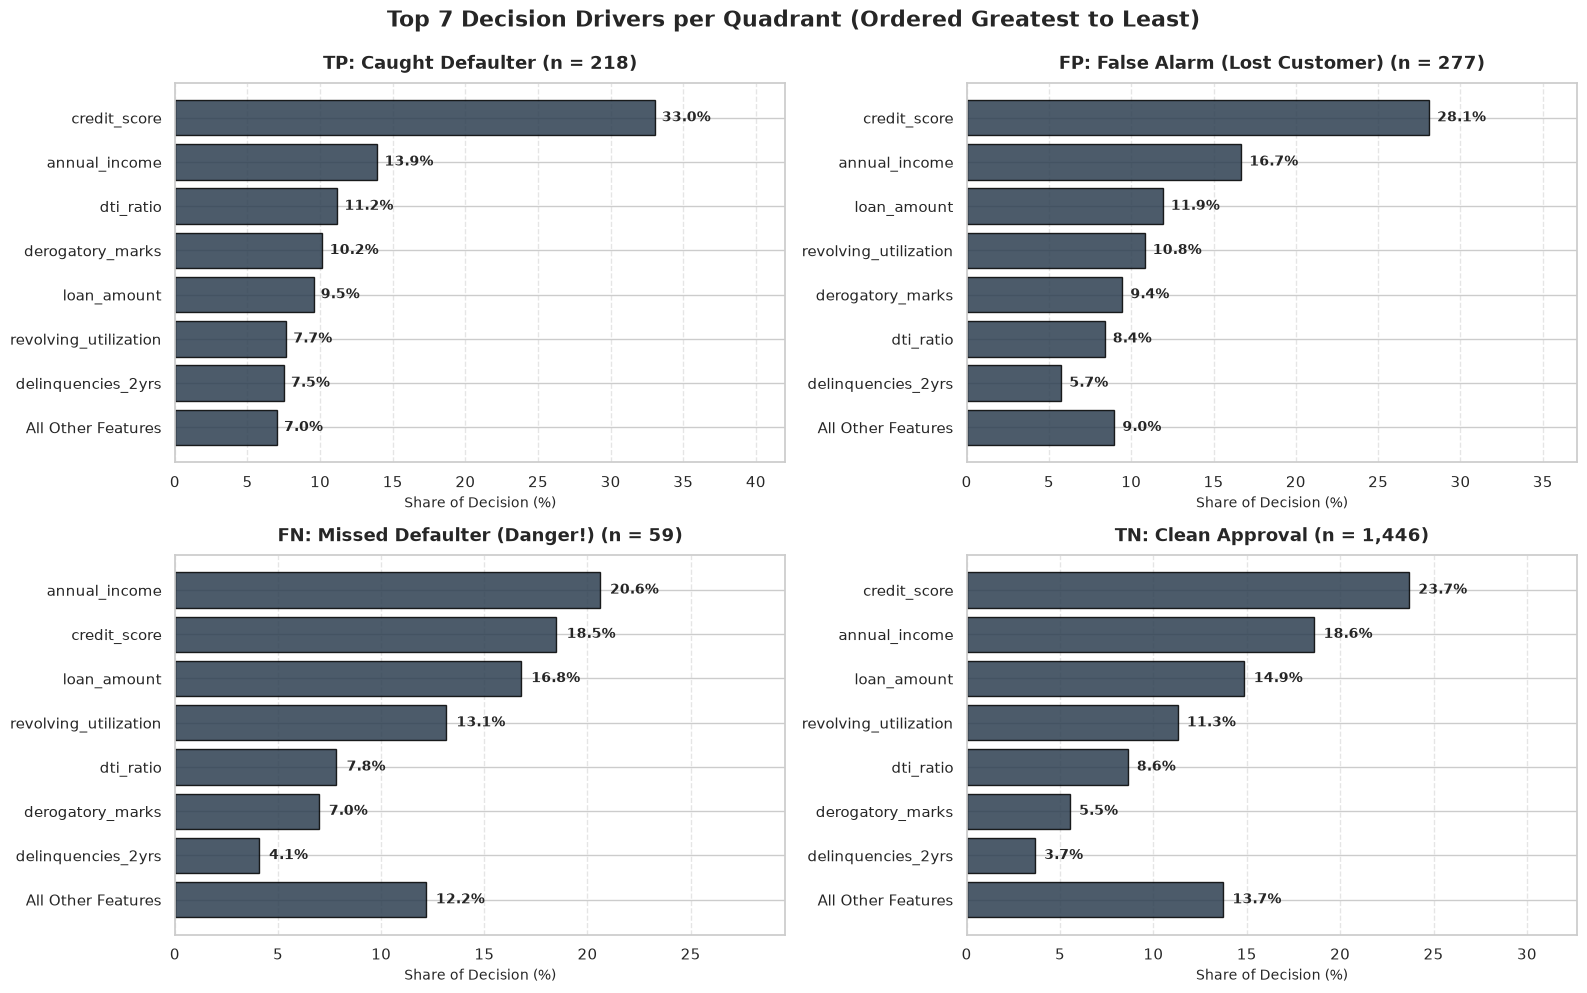

             DECISION DRIVERS BY MATRIX QUADRANT (NUMERICAL %)


,credit_score,annual_income,loan_amount,revolving_utilization,dti_ratio,derogatory_marks,delinquencies_2yrs,All Other Features
Quadrant,,,,,,,,
FN: Missed Defaulter (Danger!),18.5%,20.6%,16.8%,13.1%,7.8%,7.0%,4.1%,12.2%
FP: False Alarm (Lost Customer),28.1%,16.7%,11.9%,10.8%,8.4%,9.4%,5.7%,9.0%
TN: Clean Approval,23.7%,18.6%,14.9%,11.3%,8.6%,5.5%,3.7%,13.7%
TP: Caught Defaulter,33.0%,13.9%,9.5%,7.7%,11.2%,10.2%,7.5%,7.0%


In [54]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Compute mean absolute impact for all features across each quadrant
all_features = X_sample.columns.tolist()
quadrant_all_raw = shap_df.groupby('Quadrant')[all_features].apply(
    lambda x: np.abs(x).mean()
)

# 2. Normalize each quadrant row to 100%
quadrant_all_pct = quadrant_all_raw.div(quadrant_all_raw.sum(axis=1), axis=0) * 100

# 3. Get applicant counts per quadrant to display in titles
quadrant_counts = shap_df['Quadrant'].value_counts()

# 4. The 4 Quadrants to plot
quadrants = [
    'TP: Caught Defaulter',
    'FP: False Alarm (Lost Customer)',
    'FN: Missed Defaulter (Danger!)',
    'TN: Clean Approval',
]

# Single unified color for all charts
bar_color = '#2c3e50'  # Elegant navy/slate

# 5. Create 2x2 Subplots Dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

# Dictionary to hold the plotted numbers for the summary table
summary_dict = {}

for i, quad_name in enumerate(quadrants):
  ax = axes[i]
  count = quadrant_counts.get(quad_name, 0)

  # Pull features for this specific quadrant and sort strictly from greatest to least
  quad_series = quadrant_all_pct.loc[quad_name].sort_values(ascending=False)

  # Top 7 specific to this quadrant
  top_7 = quad_series.head(7)

  # Remainder for 'All Other Features'
  other_sum = quad_series.iloc[7:].sum()

  # Combine Top 7 + Other Bucket
  display_data = pd.concat([top_7, pd.Series({'All Other Features': other_sum})])
  summary_dict[quad_name] = display_data

  # Invert order for barh so largest is at the very top
  display_data_plot = display_data.iloc[::-1]

  # Plot horizontal bars using the same unified color
  bars = ax.barh(
      display_data_plot.index,
      display_data_plot.values,
      color=bar_color,
      alpha=0.85,
      edgecolor='black',
  )

  # Add percentage text labels
  for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f'{width:.1f}%',
        ha='left',
        va='center',
        fontsize=10,
        fontweight='bold',
    )

  ax.set_title(f'{quad_name} (n = {count:,})', fontsize=13, fontweight='bold', pad=10)
  ax.set_xlabel('Share of Decision (%)', fontsize=10)
  ax.set_xlim(0, max(display_data_plot.values) + 9)
  ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.suptitle(
    'Top 7 Decision Drivers per Quadrant (Ordered Greatest to Least)',
    fontsize=16,
    fontweight='bold',
    y=0.99,
)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 6. Display the Complete Matrix Quadrant Numbers Table
# -------------------------------------------------------------
print("=" * 80)
print("             DECISION DRIVERS BY MATRIX QUADRANT (NUMERICAL %)")
print("=" * 80)

# Pull together the top features into a clean structured comparison DataFrame
top_features_overall = (
    quadrant_all_pct.mean(axis=0).sort_values(ascending=False).head(7).index
)
matrix_numbers = quadrant_all_pct[top_features_overall].copy()
matrix_numbers['All Other Features'] = quadrant_all_pct.drop(
    columns=top_features_overall
).sum(axis=1)

# Format nicely with % symbol
display(matrix_numbers.map(lambda x: f'{x:.1f}%'))

## Summary

##### Across the entire benchmark, LightGBM came up as the top-performing default predictor with 0.6395 Test PR-AUC (and 0.8787 ROC-AUC) under 5-fold stratified cross-validation, higher than XGBoost (0.6375), Neural Network MLP (0.6318), Logistic Regression (0.6062), and Random Forest (0.5975). While global SHAP analysis showed that four core drivers (credit score, annual income, dti ratio, and revolving utilization) dictate over 70% of all underwriting decisions, slicing the confusion matrix into quadrants revealed that causes of model accuracy and error: Caught Defaulters (TP) were primarily brought down by massive credit score penalties (~35% of the total decision weight), whereas Missed Defaulters (FN) slipped past the model specifically because their deceptively clean credit scores blinded the algorithm to other emerging risk factors.